In [1]:
# ⚠️ до импорта pyarrow — CPU VM без AVX
import os
os.environ["ARROW_USER_SIMD_LEVEL"] = "NONE"

import hashlib, json, sys
import pandas as pd
import numpy as np
from datasets import load_dataset

# --- пути из ЛР1 ---
CACHE = os.path.expanduser(
    "~/.cache/huggingface/datasets/"
    "scanpatch___pii-ner-corpus-synthetic-controlled/default/0.0.0/"
    "6af0587dde068d90d8a1080285159c374b46a09b"
)
CHECKSUMS = os.path.expanduser("~/mlproject/data/CHECKSUMS.sha256")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

# --- сверка с эталоном ЛР1 ---
print("=== 1. Проверка SHA-256 (сверка с ЛР1) ===")
expected = {}
with open(CHECKSUMS) as f:
    for line in f:
        d, name = line.split(maxsplit=1)
        expected[name.strip()] = d

changed = []
for name, exp in expected.items():
    p = os.path.join(CACHE, name)
    if not os.path.exists(p):
        print(f"NOT FOUND: {name}")
        continue
    actual = sha256(p)
    if actual == exp:
        print(f"OK:       {name}")
    else:
        print(f"CHANGED:  {name}")
        print(f"  было:  {exp}")
        print(f"  стало: {actual}")
        changed.append(name)

if changed:
    print("\n⚠️ Данные изменились — обновляю CHECKSUMS.sha256")
    with open(CHECKSUMS, "w") as f:
        for name in expected:
            p = os.path.join(CACHE, name)
            if os.path.exists(p):
                f.write(f"{sha256(p)}  {name}\n")
    print("Новый эталон сохранён. Причина: перезагрузка/конвертация датасета.")

/home/mluser/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== 1. Проверка SHA-256 (сверка с ЛР1) ===
OK:       pii-ner-corpus-synthetic-controlled-test.arrow
OK:       pii-ner-corpus-synthetic-controlled-train.arrow
OK:       dataset_info.json


In [2]:
print("\n=== 2. Загрузка датасета ===")
ds = load_dataset("scanpatch/pii-ner-corpus-synthetic-controlled")
print(ds)

df_train = ds["train"].to_pandas()
df_test  = ds["test"].to_pandas()
print(f"train: {len(df_train)}, test: {len(df_test)}")
print(f"Колонки: {list(df_train.columns)}")
print(df_train.head(2))


=== 2. Загрузка датасета ===


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


DatasetDict({
    train: Dataset({
        features: ['text', 'entity_starts', 'entity_ends', 'entity_labels', 'entity_texts', 'source', 'noisy'],
        num_rows: 4786
    })
    test: Dataset({
        features: ['text', 'entity_starts', 'entity_ends', 'entity_labels', 'entity_texts', 'source', 'noisy'],
        num_rows: 532
    })
})
train: 4786, test: 532
Колонки: ['text', 'entity_starts', 'entity_ends', 'entity_labels', 'entity_texts', 'source', 'noisy']
                                                text  \
0  Виктор пролистал документы и задержал взгляд н...   
1  Раздел V. Процедуры Обслуживания и Контроль До...   

                entity_starts                   entity_ends  \
0  [0, 97, 97, 104, 247, 356]  [6, 114, 103, 114, 260, 368]   
1                          []                            []   

                                       entity_labels  \
0  [first_name, name, first_name, last_name, ip, ip]   
1                                                 []   

      

In [3]:
print("\n=== 3. Пропуски / дубликаты / типы ===")

for name, df in [("train", df_train), ("test", df_test)]:
    print(f"\n--- {name} ---")
    print(f"shape: {df.shape}")
    print(f"dtypes:\n{df.dtypes}")
    print(f"пропуски:\n{df.isna().sum()}")
    print(f"дубликаты по text: {df['text'].duplicated().sum()}")
    print(f"длина text: min={df['text'].str.len().min()}, "
          f"max={df['text'].str.len().max()}, "
          f"mean={df['text'].str.len().mean():.1f}")

# одинаковые тексты с разной разметкой — риск противоречий
for name, df in [("train", df_train), ("test", df_test)]:
    d = df[df["text"].duplicated(keep=False)]
    if len(d):
        print(f"\n{name}: {len(d)} строк с повторяющимся text")


=== 3. Пропуски / дубликаты / типы ===

--- train ---
shape: (4786, 7)
dtypes:
text                str
entity_starts    object
entity_ends      object
entity_labels    object
entity_texts     object
source              str
noisy              bool
dtype: object
пропуски:
text             0
entity_starts    0
entity_ends      0
entity_labels    0
entity_texts     0
source           0
noisy            0
dtype: int64
дубликаты по text: 6
длина text: min=1, max=3232, mean=386.9

--- test ---
shape: (532, 7)
dtypes:
text                str
entity_starts    object
entity_ends      object
entity_labels    object
entity_texts     object
source              str
noisy              bool
dtype: object
пропуски:
text             0
entity_starts    0
entity_ends      0
entity_labels    0
entity_texts     0
source           0
noisy            0
dtype: int64
дубликаты по text: 0
длина text: min=12, max=1052, mean=386.3

train: 8 строк с повторяющимся text


In [4]:
print("\n=== 4. Корректность NER-разметки ===")

allowed = set()
for df in (df_train, df_test):
    for labels in df["entity_labels"]:
        if labels is not None:
            allowed.update(labels)
print(f"Допустимые типы ({len(allowed)}): {sorted(allowed)}")

errors = []
for split, df in [("train", df_train), ("test", df_test)]:
    for idx, row in df.iterrows():
        text = row["text"] or ""
        starts, ends = row["entity_starts"], row["entity_ends"]
        labels, texts = row["entity_labels"], row["entity_texts"]
        if starts is None:
            continue
        n = len(starts)
        if not (len(ends) == n == len(labels) == len(texts)):
            errors.append(f"{split}[{idx}]: длины массивов разные")
            continue
        for s, e, l, t in zip(starts, ends, labels, texts):
            if s < 0 or s >= e:
                errors.append(f"{split}[{idx}]: неверные границы {s},{e}")
            elif e > len(text):
                errors.append(f"{split}[{idx}]: end за пределами текста {e}>{len(text)}")
            if l not in allowed:
                errors.append(f"{split}[{idx}]: неизвестный тип {l}")
            if text[s:e] != t:
                errors.append(f"{split}[{idx}]: entity_text != text[s:e]")

print(f"Ошибок: {len(errors)}")
for e in errors[:10]:
    print(" ", e)


=== 4. Корректность NER-разметки ===
Допустимые типы (27): ['address', 'address_apartment', 'address_building', 'address_city', 'address_country', 'address_district', 'address_geolocation', 'address_house', 'address_postal_code', 'address_region', 'address_street', 'date', 'document_number', 'email', 'first_name', 'ip', 'last_name', 'middle_name', 'military_individual_number', 'mobile_phone', 'name', 'name_initials', 'nickname', 'organization', 'snils', 'tin', 'vehicle_number']
Ошибок: 0


In [5]:
print("\n=== 5. Leakage train/test ===")
tr = set(df_train["text"].dropna())
te = set(df_test["text"].dropna())
overlap = tr & te
print(f"Пересечение текстов: {len(overlap)}")
if overlap:
    print("Примеры:", list(overlap)[:3])


=== 5. Leakage train/test ===
Пересечение текстов: 0



=== 6. Распределение спанов по типам ===
Всего спанов: 32500
Типов: 27
Min/Max: 28/4989 (отношение 178.2)
Медиана: 770
Типов с <100 спанов: 3
Типов с <30 спанов:  1

Топ-5:
 ip              4989
first_name      3047
name            3043
date            2774
address_city    2448
Name: count, dtype: int64

Хвост-5:
 tin                    149
address_country        114
address_apartment       76
address_postal_code     47
address_building        28
Name: count, dtype: int64


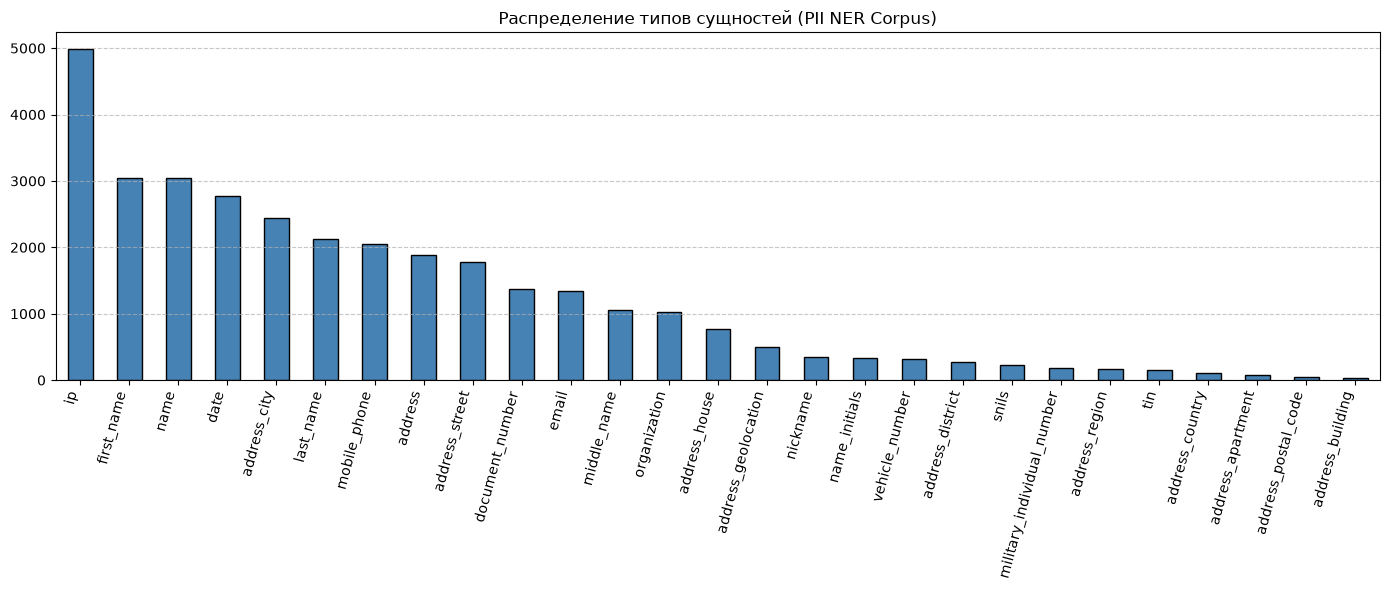

In [6]:
print("\n=== 6. Распределение спанов по типам ===")
all_labels = []
for df in (df_train, df_test):
    for labels in df["entity_labels"]:
        if labels is not None:
            all_labels.extend(labels)

counts = pd.Series(all_labels).value_counts()
print(f"Всего спанов: {counts.sum()}")
print(f"Типов: {len(counts)}")
print(f"Min/Max: {counts.min()}/{counts.max()} (отношение {counts.max()/counts.min():.1f})")
print(f"Медиана: {counts.median():.0f}")
print(f"Типов с <100 спанов: {(counts < 100).sum()}")
print(f"Типов с <30 спанов:  {(counts < 30).sum()}")
print("\nТоп-5:\n", counts.head())
print("\nХвост-5:\n", counts.tail())

# график
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))
counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Распределение типов сущностей (PII NER Corpus)")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.expanduser("~/lab2_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

In [7]:
print("\n=== 7. Негативные примеры и плотность ===")
for name, df in [("train", df_train), ("test", df_test)]:
    df = df.copy()
    df["n_ent"] = df["entity_labels"].apply(lambda x: 0 if x is None else len(x))
    print(f"\n{name}:")
    print(f"  без сущностей: {(df['n_ent']==0).sum()} "
          f"({(df['n_ent']==0).mean()*100:.1f}%)")
    print(f"  сущностей/документ: mean={df['n_ent'].mean():.2f}, "
          f"median={df['n_ent'].median():.0f}, max={df['n_ent'].max()}")


=== 7. Негативные примеры и плотность ===

train:
  без сущностей: 473 (9.9%)
  сущностей/документ: mean=6.13, median=5, max=48

test:
  без сущностей: 58 (10.9%)
  сущностей/документ: mean=5.94, median=5, max=42


In [8]:
print("\n=== 8. Итоги и артефакты ===")

art = os.path.expanduser("~/mlproject/artifacts")
os.makedirs(art, exist_ok=True)

summary = {
    "dataset": "scanpatch/pii-ner-corpus-synthetic-controlled",
    "splits": {"train": len(df_train), "test": len(df_test)},
    "columns": list(df_train.columns),
    "n_entity_types": int(len(counts)),
    "n_spans_total": int(counts.sum()),
    "min_per_type": int(counts.min()),
    "max_per_type": int(counts.max()),
    "types_lt_100_spans": int((counts < 100).sum()),
    "types_lt_30_spans":  int((counts < 30).sum()),
    "negatives_train": int((df_train["entity_labels"].apply(
        lambda x: 0 if x is None else len(x)) == 0).sum()),
    "negatives_test": int((df_test["entity_labels"].apply(
        lambda x: 0 if x is None else len(x)) == 0).sum()),
    "label_errors": len(errors),
    "leakage_texts": len(overlap),
}
with open(f"{art}/data_quality_report.json", "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(json.dumps(summary, indent=2, ensure_ascii=False))
print(f"\nСохранено: {art}/data_quality_report.json")


=== 8. Итоги и артефакты ===
{
  "dataset": "scanpatch/pii-ner-corpus-synthetic-controlled",
  "splits": {
    "train": 4786,
    "test": 532
  },
  "columns": [
    "text",
    "entity_starts",
    "entity_ends",
    "entity_labels",
    "entity_texts",
    "source",
    "noisy"
  ],
  "n_entity_types": 27,
  "n_spans_total": 32500,
  "min_per_type": 28,
  "max_per_type": 4989,
  "types_lt_100_spans": 3,
  "types_lt_30_spans": 1,
  "negatives_train": 473,
  "negatives_test": 58,
  "label_errors": 0,
  "leakage_texts": 0
}

Сохранено: /home/mluser/mlproject/artifacts/data_quality_report.json
